# Assignment 8: Noise Generation

Generate the following noise types using equations derived from their probability density functions (PDFs), compare them with inbuilt functions, and plot their histograms to check the shape of each distribution:

1. Uniform noise
2. Gaussian noise
3. Erlang noise
4. Exponential noise
5. Rayleigh noise

**Requirements:** `pip install numpy matplotlib opencv-python scikit-image`

### Note on `imnoise`

`imnoise` is a MATLAB function. Its modes are `gaussian`, `localvar`, `poisson`, `salt & pepper` and `speckle`, so of the five noise types above it only supports **Gaussian**. This notebook therefore compares against:

| Noise | Inbuilt function used |
|---|---|
| Gaussian | `skimage.util.random_noise(mode="gaussian")`, the Python equivalent of `imnoise` |
| Uniform | `numpy.random.Generator.uniform` |
| Erlang | `numpy.random.Generator.gamma` (Erlang is a gamma distribution with integer shape) |
| Exponential | `numpy.random.Generator.exponential` |
| Rayleigh | `numpy.random.Generator.rayleigh` |

## Setup

To use your own image, set `INPUT_PATH`, for example `INPUT_PATH = "input.jpg"`. If it is left as `None`, a sample image from scikit-image is used. All noise values are in gray levels (0 to 255).

In [1]:
import math

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.util import random_noise

INPUT_PATH = None
SEED = 42

# Noise parameters
UNIFORM_A, UNIFORM_B = -40, 40      # lower and upper limits
GAUSSIAN_MEAN, GAUSSIAN_STD = 0, 25
ERLANG_A, ERLANG_B = 0.2, 4         # b must be a positive integer
EXPONENTIAL_A = 0.05
RAYLEIGH_A, RAYLEIGH_B = 0, 1000

if INPUT_PATH is None:
    image = data.camera()
else:
    image = cv2.imread(INPUT_PATH, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {INPUT_PATH}")

shape = image.shape
rng_own = np.random.default_rng(SEED)
rng_inbuilt = np.random.default_rng(SEED + 1)
print("Image shape:", shape)

Image shape: (512, 512)


## Deriving the equations

Every generator below starts from uniform random numbers $U \in [0, 1)$, which is the only random source used.

The **inverse transform method** sets the CDF equal to $U$ and solves for $z$: if $F(z) = U$, then $z = F^{-1}(U)$ follows the required distribution.

### 1. Uniform

$$p(z) = \frac{1}{b-a}, \quad a \le z \le b \qquad\Rightarrow\qquad F(z) = \frac{z-a}{b-a} = U \qquad\Rightarrow\qquad z = a + (b-a)U$$

### 2. Gaussian

$$p(z) = \frac{1}{\sqrt{2\pi}\,\sigma} e^{-(z-\mu)^2/2\sigma^2}$$

The Gaussian CDF has no closed-form inverse, so the **Box-Muller transform** is used. It converts two independent uniform numbers into a Gaussian value:

$$z = \mu + \sigma\sqrt{-2\ln(1-U_1)}\,\cos(2\pi U_2)$$

### 3. Erlang

$$p(z) = \frac{a^b z^{b-1}}{(b-1)!} e^{-az}, \quad z \ge 0$$

An Erlang variable is the sum of $b$ independent exponential variables with parameter $a$:

$$z = -\frac{1}{a}\sum_{i=1}^{b} \ln(1-U_i)$$

### 4. Exponential

$$p(z) = a e^{-az}, \quad z \ge 0 \qquad\Rightarrow\qquad F(z) = 1 - e^{-az} = U \qquad\Rightarrow\qquad z = -\frac{1}{a}\ln(1-U)$$

### 5. Rayleigh

$$p(z) = \frac{2}{b}(z-a)e^{-(z-a)^2/b}, \quad z \ge a \qquad\Rightarrow\qquad F(z) = 1 - e^{-(z-a)^2/b} = U \qquad\Rightarrow\qquad z = a + \sqrt{-b\ln(1-U)}$$

### Summary of means and variances

| Noise | Mean | Variance |
|---|---|---|
| Uniform | $(a+b)/2$ | $(b-a)^2/12$ |
| Gaussian | $\mu$ | $\sigma^2$ |
| Erlang | $b/a$ | $b/a^2$ |
| Exponential | $1/a$ | $1/a^2$ |
| Rayleigh | $a+\sqrt{\pi b/4}$ | $b(4-\pi)/4$ |

## Noise generators from the equations

In [2]:
def uniform_noise(shape, a, b, rng):
    return a + (b - a) * rng.random(shape)


def gaussian_noise(shape, mean, std, rng):
    u1, u2 = rng.random(shape), rng.random(shape)
    return mean + std * np.sqrt(-2 * np.log(1 - u1)) * np.cos(2 * np.pi * u2)


def exponential_noise(shape, a, rng):
    return -np.log(1 - rng.random(shape)) / a


def erlang_noise(shape, a, b, rng):
    total = np.zeros(shape)
    for _ in range(b):
        total += exponential_noise(shape, a, rng)
    return total


def rayleigh_noise(shape, a, b, rng):
    return a + np.sqrt(-b * np.log(1 - rng.random(shape)))

## Inbuilt noise

`random_noise` works on images in the range 0 to 1, so its parameters are scaled and its output converted back to gray levels.

NumPy's Rayleigh PDF is $\frac{z}{s^2}e^{-z^2/2s^2}$. Comparing this with the equation above gives $b = 2s^2$, so $s = \sqrt{b/2}$.

In [3]:
def inbuilt_gaussian(img, mean, std):
    """Python equivalent of MATLAB's imnoise(img, 'gaussian', mean, var)."""
    f = img / 255.0
    noisy = random_noise(f, mode="gaussian", mean=mean / 255, var=(std / 255) ** 2, clip=False)
    return (noisy - f) * 255


own = {
    "Uniform": uniform_noise(shape, UNIFORM_A, UNIFORM_B, rng_own),
    "Gaussian": gaussian_noise(shape, GAUSSIAN_MEAN, GAUSSIAN_STD, rng_own),
    "Erlang": erlang_noise(shape, ERLANG_A, ERLANG_B, rng_own),
    "Exponential": exponential_noise(shape, EXPONENTIAL_A, rng_own),
    "Rayleigh": rayleigh_noise(shape, RAYLEIGH_A, RAYLEIGH_B, rng_own),
}

inbuilt = {
    "Uniform": rng_inbuilt.uniform(UNIFORM_A, UNIFORM_B, shape),
    "Gaussian": inbuilt_gaussian(image, GAUSSIAN_MEAN, GAUSSIAN_STD),
    "Erlang": rng_inbuilt.gamma(ERLANG_B, 1 / ERLANG_A, shape),
    "Exponential": rng_inbuilt.exponential(1 / EXPONENTIAL_A, shape),
    "Rayleigh": RAYLEIGH_A + rng_inbuilt.rayleigh(math.sqrt(RAYLEIGH_B / 2), shape),
}


def theoretical_pdf(name, z):
    """The PDF from the equations above, used as a reference on the histograms."""
    if name == "Uniform":
        return np.where((z >= UNIFORM_A) & (z <= UNIFORM_B), 1 / (UNIFORM_B - UNIFORM_A), 0.0)
    if name == "Gaussian":
        return np.exp(-(z - GAUSSIAN_MEAN) ** 2 / (2 * GAUSSIAN_STD**2)) / (math.sqrt(2 * math.pi) * GAUSSIAN_STD)
    if name == "Erlang":
        a, b = ERLANG_A, ERLANG_B
        return np.where(z >= 0, a**b * np.maximum(z, 0) ** (b - 1) * np.exp(-a * z) / math.factorial(b - 1), 0.0)
    if name == "Exponential":
        return np.where(z >= 0, EXPONENTIAL_A * np.exp(-EXPONENTIAL_A * z), 0.0)
    a, b = RAYLEIGH_A, RAYLEIGH_B
    return np.where(z >= a, (2 / b) * (z - a) * np.exp(-((z - a) ** 2) / b), 0.0)


theoretical_stats = {
    "Uniform": ((UNIFORM_A + UNIFORM_B) / 2, (UNIFORM_B - UNIFORM_A) ** 2 / 12),
    "Gaussian": (GAUSSIAN_MEAN, GAUSSIAN_STD**2),
    "Erlang": (ERLANG_B / ERLANG_A, ERLANG_B / ERLANG_A**2),
    "Exponential": (1 / EXPONENTIAL_A, 1 / EXPONENTIAL_A**2),
    "Rayleigh": (RAYLEIGH_A + math.sqrt(math.pi * RAYLEIGH_B / 4), RAYLEIGH_B * (4 - math.pi) / 4),
}

## Noisy images and histograms

Each row shows the image with noise from the equations, the image with noise from the inbuilt function, and the histograms of both noise samples. The black line is the theoretical PDF.

The histograms are computed from the noise itself, before the noisy image is clipped to the 0 to 255 range.

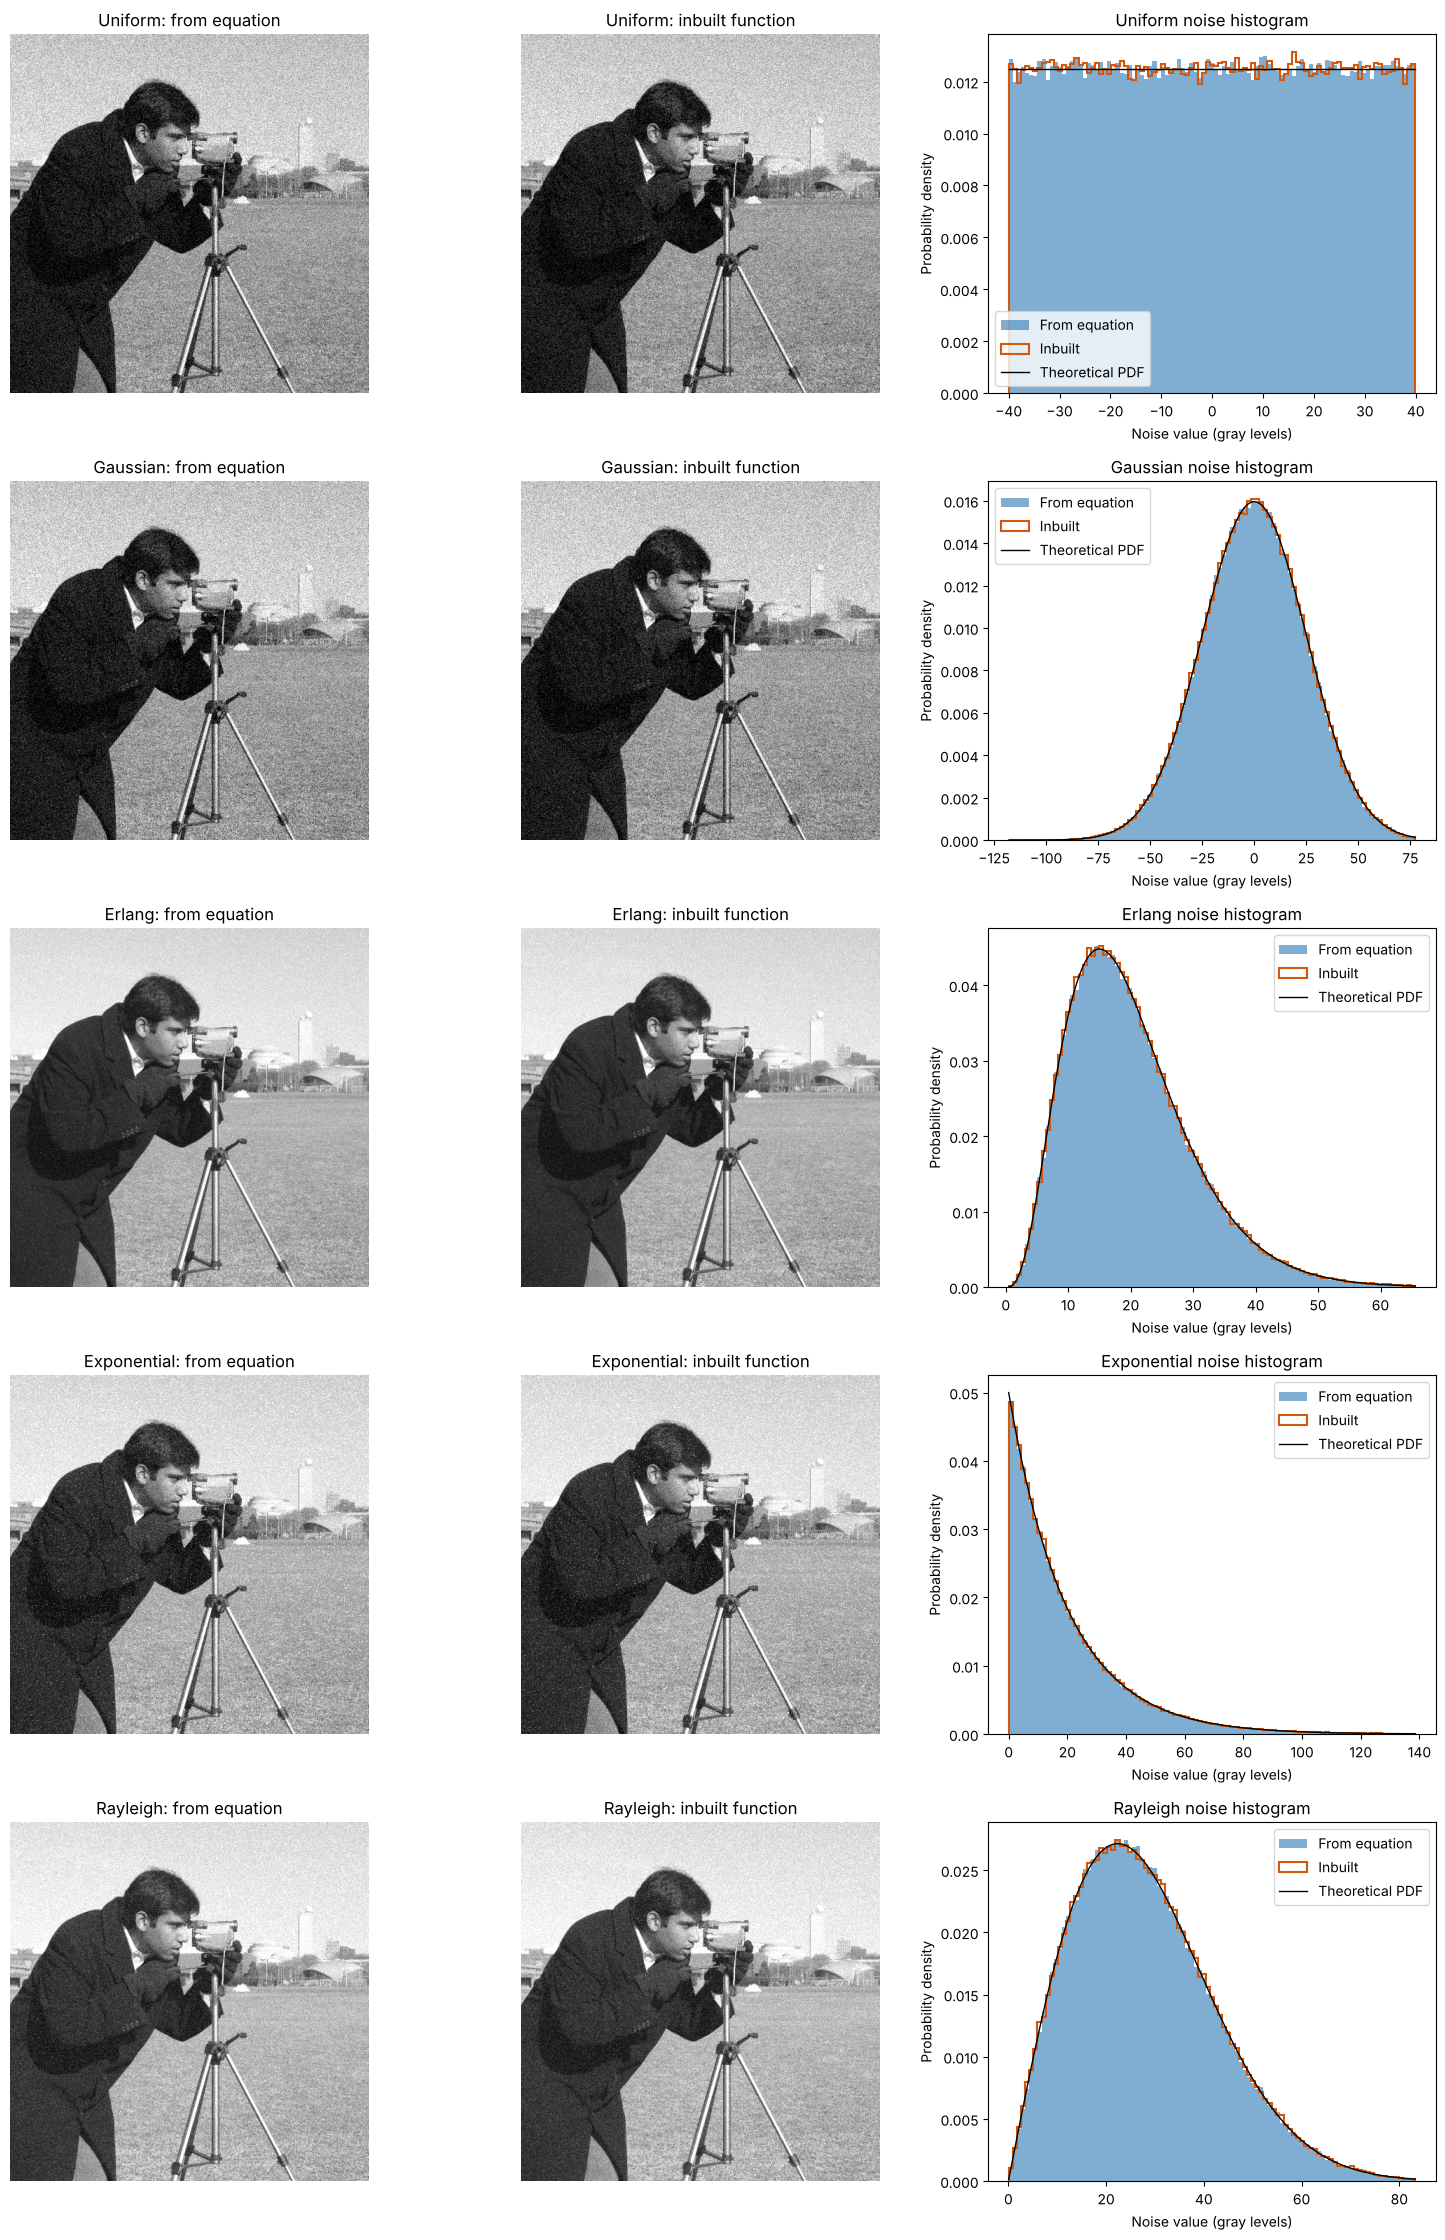

In [4]:
def add_noise(img, noise):
    return np.clip(np.round(img + noise), 0, 255).astype(np.uint8)


fig, axes = plt.subplots(len(own), 3, figsize=(15, 4.5 * len(own)))
for row, name in zip(axes, own):
    row[0].imshow(add_noise(image, own[name]), cmap="gray", vmin=0, vmax=255)
    row[0].set_title(f"{name}: from equation")
    row[0].axis("off")

    row[1].imshow(add_noise(image, inbuilt[name]), cmap="gray", vmin=0, vmax=255)
    row[1].set_title(f"{name}: inbuilt function")
    row[1].axis("off")

    low = min(own[name].min(), inbuilt[name].min())
    high = np.percentile(np.concatenate([own[name].ravel(), inbuilt[name].ravel()]), 99.9)
    bins = np.linspace(low, high, 100)
    row[2].hist(own[name].ravel(), bins=bins, density=True, color="#2a78b5", alpha=0.6, label="From equation")
    row[2].hist(inbuilt[name].ravel(), bins=bins, density=True, histtype="step", color="#d1580e",
                linewidth=1.5, label="Inbuilt")
    z = np.linspace(low, high, 800)
    row[2].plot(z, theoretical_pdf(name, z), color="black", linewidth=1, label="Theoretical PDF")
    row[2].set_title(f"{name} noise histogram")
    row[2].set_xlabel("Noise value (gray levels)")
    row[2].set_ylabel("Probability density")
    row[2].legend()

plt.tight_layout()
plt.show()

## Numerical comparison

In [5]:
print(f"{'Noise':<13}{'Mean':>10}{'Mean':>10}{'Mean':>10}{'Var':>12}{'Var':>12}{'Var':>12}")
print(f"{'':<13}{'theory':>10}{'equation':>10}{'inbuilt':>10}{'theory':>12}{'equation':>12}{'inbuilt':>12}")
print("-" * 79)
for name in own:
    mean, var = theoretical_stats[name]
    print(f"{name:<13}{mean:>10.2f}{own[name].mean():>10.2f}{inbuilt[name].mean():>10.2f}"
          f"{var:>12.2f}{own[name].var():>12.2f}{inbuilt[name].var():>12.2f}")

Noise              Mean      Mean      Mean         Var         Var         Var
                 theory  equation   inbuilt      theory    equation     inbuilt
-------------------------------------------------------------------------------
Uniform            0.00      0.01     -0.02      533.33      533.60      533.61
Gaussian           0.00     -0.03     -0.08      625.00      624.70      625.85
Erlang            20.00     19.99     19.99      100.00      100.33      100.10
Exponential       20.00     20.04     19.96      400.00      401.89      399.03
Rayleigh          28.02     28.01     28.05      214.60      214.19      215.26


## Conclusion

The histograms confirm the expected shape of each distribution:

- **Uniform:** flat between $a$ and $b$.
- **Gaussian:** a symmetric bell curve centred on the mean.
- **Erlang:** skewed to the right, rising from zero to a peak and then decaying.
- **Exponential:** highest at zero, then decaying steadily.
- **Rayleigh:** starts at $a$, rises quickly and has a long tail to the right.

For all five types, the noise generated from the equations closely matches both the inbuilt functions and the theoretical mean, variance and PDF.